# Part 2 — Agentic Exploratory Data Analysis (Bike Sharing Demand)

**CMPE 255 | Part 2 | Google Colab**

**Goal:** Use a Gemini-based **tool-calling data analysis agent**, not hand-written analysis questions, to investigate the Bike Sharing Demand dataset. The agent decides which available Python analysis tools to call based on a natural-language request. We then validate its claims using deterministic Pandas calculations and save evidence for GitHub.

**Prerequisites:** A Gemini API key from [Google AI Studio](https://aistudio.google.com/apikey). This notebook uses `google-genai` (not AutoViML or PandasAI). Keep your key private. Some Gemini API requests may incur charges. AI-generated tool calls should only run on trusted datasets.

**Data:** [Bike Sharing Demand — Kaggle](https://www.kaggle.com/competitions/bike-sharing-demand/data). The dataset includes hourly rentals, weather and calendar information.

**Note:** This is an agentic EDA demonstration, *not* a new forecasting model. It reuses the Part 1B dataset for a controlled manual-vs-agent comparison.

## 0 — Install the compatible packages

In [13]:
%pip install -q \
    "google-genai>=2.12.1,<3" \
    "tenacity>=9,<10"



In [14]:

from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")

if api_key:
    print("Gemini API key loaded successfully!")
else:
    print("API key not found.")

Gemini API key loaded successfully!


## 1 — Load Kaggle bike sharing data automatically

A public mirror is tried first. If it is unavailable or fails schema validation, the cell requests the original `train.csv` upload from Kaggle.

In [15]:
from pathlib import Path
import io, requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

OUT = Path('/content/part2_outputs')
OUT.mkdir(exist_ok=True)
mirror = 'https://raw.githubusercontent.com/cretlaw/Bike_Sharing_Demand/master/train.csv'
try:
    response = requests.get(mirror, timeout=35)
    response.raise_for_status()
    df = pd.read_csv(io.BytesIO(response.content))
    required = {'datetime','season','holiday','workingday','weather','temp','atemp','humidity','windspeed','count'}
    assert required.issubset(set(df.columns)), 'The mirror did not return the expected Kaggle schema'
    print('Loaded Kaggle Bike Sharing Demand from public mirror')
except Exception as exc:
    print('Automatic download failed:', exc)
    print('Upload train.csv from the Kaggle Bike Sharing Demand competition.')
    from google.colab import files
    uploaded = files.upload()
    if 'train.csv' not in uploaded:
        raise ValueError('Please upload the file named train.csv')
    df = pd.read_csv(io.BytesIO(uploaded['train.csv']))

df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df = df.sort_values('datetime').reset_index(drop=True)
df['hour'] = df['datetime'].dt.hour
df['weekday'] = df['datetime'].dt.day_name()
df['month'] = df['datetime'].dt.month
print('Shape:', df.shape, '| Dates:', df.datetime.min(), 'to', df.datetime.max())
display(df.head())

Loaded Kaggle Bike Sharing Demand from public mirror
Shape: (10886, 15) | Dates: 2011-01-01 00:00:00 to 2012-12-19 23:00:00


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour,weekday,month
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,0,Saturday,1
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,1,Saturday,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2,Saturday,1
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,3,Saturday,1
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,4,Saturday,1


## 2 — Provide your Gemini key securely

In Colab choose the **Secrets** key icon, create a secret called `GEMINI_API_KEY`, and enable notebook access. If Secrets are not configured, the cell will prompt privately. Do not paste or commit your key to GitHub.

In [16]:
import os, getpass
try:
    from google.colab import userdata
    api_key = userdata.get('GEMINI_API_KEY')
except Exception:
    api_key = None
if not api_key:
    api_key = getpass.getpass('Enter your Gemini API key (hidden): ')
if not api_key:
    raise RuntimeError('A Gemini API key is required for the agent demonstration.')
from google import genai
from google.genai import types
client = genai.Client(api_key=api_key)
MODEL = "gemini-3.8-flash"  # Change if your API account does not support this model
print('Gemini client initialized; secret not displayed.')

Gemini client initialized; secret not displayed.


## 3 — Define trustworthy data tools the agent can use

These are reusable operations, not pre-written answers. The LLM selects which function(s) to invoke. Functions return concise computed evidence. This avoids executing arbitrary generated Python code.

In [17]:
tool_log = []
def record(name, result):
    tool_log.append({'tool': name, 'result': result})
    return result

def dataset_overview() -> dict:
    """Return dataset row/column counts, date range, columns, duplicates and numeric summary."""
    numeric = df.select_dtypes(include='number').describe().round(2)
    result = {'rows':len(df), 'columns':list(df.columns), 'start':str(df.datetime.min()),
              'end':str(df.datetime.max()), 'duplicate_rows':int(df.duplicated().sum()),
              'numeric_summary':numeric.loc[['mean','std','min','max']].to_dict()}
    return record('dataset_overview',result)

def missing_data_report() -> dict:
    """Calculate missing values per column, percentage missing, duplicate timestamps and invalid targets."""
    missing = df.isna().sum().sort_values(ascending=False)
    result = {'missing_values':{k:int(v) for k,v in missing.items()},
              'missing_percent':{k:round(float(v),2) for k,v in (missing/len(df)*100).items()},
              'duplicate_timestamps':int(df.datetime.duplicated().sum()),
              'negative_count_rows':int((df['count']<0).sum())}
    return record('missing_data_report',result)

def demand_by_group(group: str) -> dict:
    """Summarize average bicycle rental count by a group. Args: group: one of hour, weekday, month, season, weather, holiday, workingday."""
    allowed={'hour','weekday','month','season','weather','holiday','workingday'}
    if group not in allowed: return record('demand_by_group',{'error':f'Invalid group: {group}'})
    t=df.groupby(group)['count'].agg(['count','mean','median']).round(2).reset_index()
    result={'group':group, 'rows':t.to_dict(orient='records')}
    return record('demand_by_group',result)

def correlations_with_demand() -> dict:
    """Return numeric Pearson correlations with hourly bike rental count."""
    vals=df.select_dtypes(include='number').corr(numeric_only=True)['count'].sort_values(ascending=False)
    result={k:round(float(v),3) for k,v in vals.items() if pd.notna(v)}
    return record('correlations_with_demand',result)

def extreme_demand_hours(quantile: float = 0.99) -> dict:
    """Find extreme high-demand observations using a quantile. Args: quantile: a number from 0.9 to 0.999."""
    q=float(quantile)
    if not 0.9<=q<=0.999:return record('extreme_demand_hours',{'error':'quantile must be between 0.9 and 0.999'})
    threshold=float(df['count'].quantile(q))
    rows=df.loc[df['count']>=threshold,['datetime','count','hour','temp','humidity','weather']].head(10).copy()
    rows['datetime']=rows['datetime'].astype(str)
    result={'quantile':q,'threshold':round(threshold,2),'total_extreme_rows':int((df['count']>=threshold).sum()),'examples':rows.to_dict('records')}
    return record('extreme_demand_hours',result)

def demand_by_temperature() -> dict:
    """Summarize average bike rentals across temperature quartile groups."""
    bins=pd.qcut(df['temp'],q=4,duplicates='drop')
    table=df.groupby(bins,observed=True)['count'].agg(['count','mean']).round(2)
    result={str(k):{'rows':int(row['count']),'average_rentals':float(row['mean'])} for k,row in table.iterrows()}
    return record('demand_by_temperature',result)

TOOLS=[dataset_overview,missing_data_report,demand_by_group,correlations_with_demand,extreme_demand_hours,demand_by_temperature]
print('Agent tools:',[f.__name__ for f in TOOLS])

Agent tools: ['dataset_overview', 'missing_data_report', 'demand_by_group', 'correlations_with_demand', 'extreme_demand_hours', 'demand_by_temperature']


## 4 — Ask the AI agent to explore data

This is the **core Part 2 demonstration**. Notice that we do not tell it to run specific Pandas lines. It chooses tools based on our investigation goal.

In [18]:
prompt = """Act as a data-science EDA agent. Investigate this Washington DC hourly bike-rental dataset.
Use the available tools to inspect its structure, data quality, temporal rental patterns,
weather relationships, and unusually high-demand hours. Call at least 4 different tools.
Report (1) grounded quantitative findings, (2) data-quality concerns,
(3) possible operational uses, and (4) important limitations. Do not invent data or
claim causality from correlation. Count = total rentals; casual and registered must
not be used as predictors of count because they sum to the target.
"""
response = client.models.generate_content(
    model=MODEL,
    contents=prompt,
    config=types.GenerateContentConfig(
        temperature=0,
        tools=TOOLS,
        automatic_function_calling=types.AutomaticFunctionCallingConfig(maximum_remote_calls=10),
    )
)
print('AGENT RESPONSE:')
print(response.text or '(No text response returned; inspect tool_log)')
print('\nTools called:',[item['tool'] for item in tool_log])
if len(set(item['tool'] for item in tool_log)) < 4:
    print('NOTE: Agent used fewer than four distinct tools. Ask a targeted follow-up and document the actual calls.')
(OUT/'agent_report.txt').write_text(response.text or '',encoding='utf-8')

AGENT RESPONSE:
### Exploratory Data Analysis: Washington D.C. Hourly Bike-Rental Dataset

---

### 1. Grounded Quantitative Findings

#### **Dataset Overview & Volume**
* **Records and Window:** 10,886 hourly records spanning from **January 1, 2011 00:00:00** to **December 19, 2012 23:00:00**.
* **Rental Distribution:** Hourly total rentals (`count`) average **191.57** ($\sigma = 181.14$, min = 1, max = 977).
* **Rider Breakdown:** Total demand is composed of registered users ($\mu = 155.55$, $\sigma = 151.04$) and casual users ($\mu = 36.02$, $\sigma = 49.96$). Registered riders represent approximately **81.2%** of aggregate demand. *(Note: Casual and registered sum identically to count and are excluded from predictor evaluations).*

#### **Temporal Demand Dynamics**
* **Hourly Peaks (Bimodal Commuter Pattern):**
  * Demand exhibits pronounced commuter peaks:
    * **Morning commute:** 08:00 averages **362.77** rentals (median: 392).
    * **Evening commute:** 17:00 averages **468.77

5903

## 5 — Interactive follow-up question

Demonstrate a second natural-language question. Change the query to investigate a hypothesis not answered in the first request.

In [19]:
question = "Compare average rental demand across the hours of the day, and identify the two highest-demand hours. Give the actual averages."
followup = client.models.generate_content(
    model=MODEL,
    contents=question,
    config=types.GenerateContentConfig(
        tools=TOOLS,
        temperature=0,
        automatic_function_calling=types.AutomaticFunctionCallingConfig(maximum_remote_calls=5)
    )
)
print('USER:',question)
print('AGENT:',followup.text)
(OUT/'agent_followup.txt').write_text(followup.text or '',encoding='utf-8')

USER: Compare average rental demand across the hours of the day, and identify the two highest-demand hours. Give the actual averages.
AGENT: ### Hourly Rental Demand Comparison

Rental demand exhibits a distinct bimodal pattern, driven strongly by typical commuting schedules:

* **Overnight / Early Morning Trough (12:00 AM – 5:00 AM):** Demand drops to its lowest levels of the day, bottoming out at **4:00 AM** with an average of **6.41 rentals**.
* **Morning Commute Peak (7:00 AM – 9:00 AM):** Demand ramps up sharply starting at 6:00 AM, peaking at **8:00 AM** with an average of **362.77 rentals**.
* **Midday Steady Period (10:00 AM – 3:00 PM):** Demand stabilizes between approximately **175** and **258 rentals/hour**.
* **Evening Commute Peak (4:00 PM – 7:00 PM):** Demand reaches its highest levels of the entire day, driven by afternoon commuters.
* **Evening Wind-down (8:00 PM – 11:00 PM):** Demand tapers off steadily from **228.52** at 8:00 PM down to **89.51** at 11:00 PM.

---

##

1957

## 6 — Verify the agent

A model-generated narrative is not proof. Compute simple independent checks and compare with claims made by the agent. The **manual verification** below is a correctness audit, not the main EDA method.

In [20]:
verification = {
  'rows':int(len(df)),
  'missing_total':int(df.isna().sum().sum()),
  'duplicate_timestamps':int(df.datetime.duplicated().sum()),
  'highest_mean_hour':int(df.groupby('hour')['count'].mean().idxmax()),
  'highest_hour_mean':round(float(df.groupby('hour')['count'].mean().max()),2),
  'lowest_mean_hour':int(df.groupby('hour')['count'].mean().idxmin()),
  'overall_mean_rentals':round(float(df['count'].mean()),2),
  'corr_temp_count':round(float(df[['temp','count']].corr().iloc[0,1]),3)
}
print('INDEPENDENT CHECKS:')
for k,v in verification.items(): print(k,':',v)
import json
(OUT/'verification.json').write_text(json.dumps(verification,indent=2))
print('Compare these values with the agent response and note any discrepancy in your report.')

INDEPENDENT CHECKS:
rows : 10886
missing_total : 0
duplicate_timestamps : 0
highest_mean_hour : 17
highest_hour_mean : 468.77
lowest_mean_hour : 4
overall_mean_rentals : 191.57
corr_temp_count : 0.394
Compare these values with the agent response and note any discrepancy in your report.


## 7 — Render and export evidence charts

Plots are generated deterministically from the data to provide presentation-ready evidence for the agent’s findings.

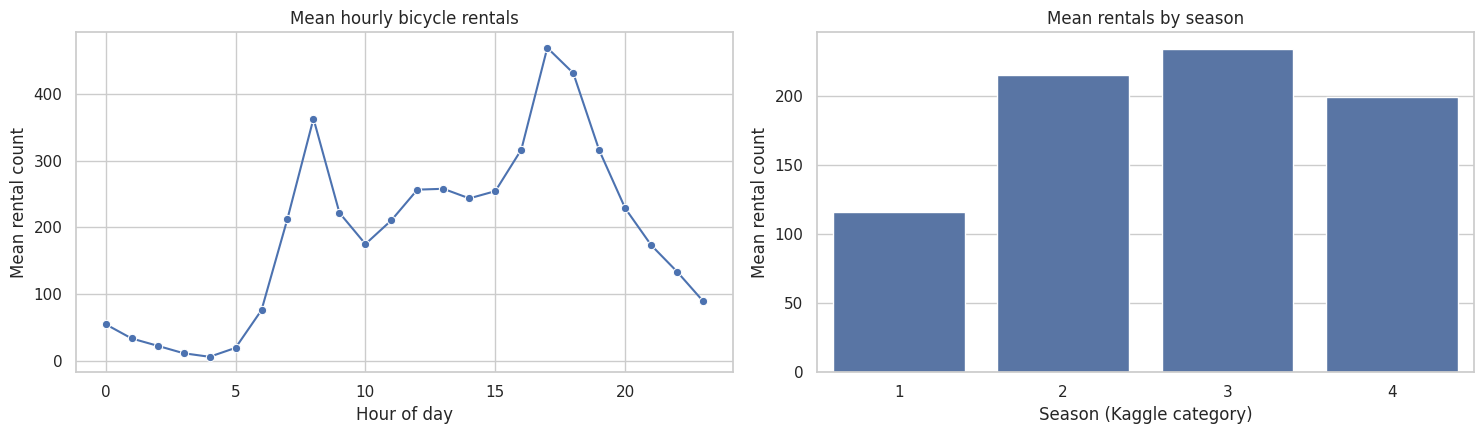

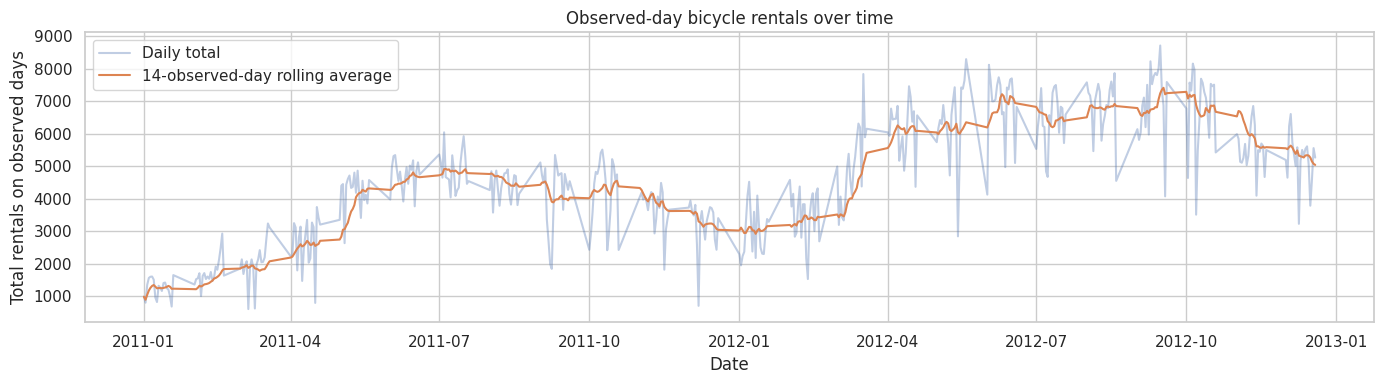

Charts saved under /content/part2_outputs


In [21]:
sns.set_theme(style='whitegrid')
fig,axes=plt.subplots(1,2,figsize=(15,4.5))
hourly=df.groupby('hour')['count'].mean()
sns.lineplot(x=hourly.index,y=hourly.values,marker='o',ax=axes[0])
axes[0].set(title='Mean hourly bicycle rentals',xlabel='Hour of day',ylabel='Mean rental count')
season=df.groupby('season')['count'].mean()
sns.barplot(x=season.index.astype(str),y=season.values,ax=axes[1])
axes[1].set(title='Mean rentals by season',xlabel='Season (Kaggle category)',ylabel='Mean rental count')
fig.tight_layout()
fig.savefig(OUT/'temporal_patterns.png',dpi=160,bbox_inches='tight')
plt.show()

daily=df.groupby(df['datetime'].dt.floor('D'))['count'].sum()
fig,ax=plt.subplots(figsize=(14,4))
ax.plot(daily.index,daily.values,alpha=.35,label='Daily total')
ax.plot(daily.rolling(14,min_periods=1).mean(),label='14-observed-day rolling average')
ax.set(title='Observed-day bicycle rentals over time',xlabel='Date',ylabel='Total rentals on observed days')
ax.legend(); fig.tight_layout()
fig.savefig(OUT/'daily_trend.png',dpi=160,bbox_inches='tight');plt.show()
print('Charts saved under',OUT)

## 8 — Export agent trace and files for GitHub

In [22]:
from datetime import datetime, timezone
trace={'generated_utc':datetime.now(timezone.utc).isoformat(),
       'model':MODEL,'prompt':prompt,
       'tool_calls':tool_log,
       'note':'This captures tool evidence, not the provider internal reasoning process.'}
(OUT/'tool_trace.json').write_text(json.dumps(trace,indent=2,default=str),encoding='utf-8')
print('Saved:',sorted(p.name for p in OUT.iterdir()))
# Uncomment to download evidence as a ZIP from Colab:
# import shutil
# shutil.make_archive('/content/part2_evidence','zip',OUT)
# from google.colab import files
# files.download('/content/part2_evidence.zip')

Saved: ['agent_followup.txt', 'agent_report.txt', 'daily_trend.png', 'temporal_patterns.png', 'tool_trace.json', 'verification.json']


## Part 2 — Agentic EDA Evaluation and Findings

A Gemini-powered data analysis agent was developed to perform exploratory analysis on the Washington D.C. Bike Sharing Demand dataset. The agent received natural-language instructions and independently selected dataset-analysis functions to investigate distributions, missing data, temporal demand patterns, weather relationships, and extreme rental observations.

The agent recorded nine function calls across five distinct analysis tools. Its findings included 10,886 hourly records, no reported missing values, a mean rental count of 191.57, and two prominent demand peaks associated with commuting periods.

The highest average demand occurred at 5 PM (468.77 rentals), followed by 6 PM (430.86 rentals). The agent also identified a positive relationship between temperature and rental demand and a negative relationship between humidity and demand.

Data-quality findings included systematic missing calendar dates caused by Kaggle's dataset partitioning, an extremely rare weather category, and potentially unusual wind-speed measurements.

The agent demonstrated the ability to select analytical tools, retrieve quantitative findings, and generate natural-language business interpretations. Its output also illustrated why independent validation is necessary: seasonal labels and some interpretations required correction or additional evidence.

Overall, the project demonstrates how agentic AI can automate significant portions of exploratory data analysis while retaining human oversight for statistical accuracy and practical recommendations.